In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load Dataset
df = pd.read_csv('../data/Sleep_health_and_lifestyle_dataset.csv')

# Data Selection: Hapus kolom 'Person ID'
df_selected = df.drop(columns=['Person ID'])
df_selected.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
df_clean = df_selected.copy()

# Handling Missing Values pada 'Sleep Disorder'
df_clean['Sleep Disorder'] = df_clean['Sleep Disorder'].fillna('None')

# Feature Engineering pada 'Blood Pressure'
df_clean[['BP_Systolic', 'BP_Diastolic']] = df_clean['Blood Pressure'].str.split('/', expand=True).astype(int)
df_clean.drop(columns=['Blood Pressure'], inplace=True)
df_clean.head()

C:\Users\rochy\AppData\Local\Temp\ipykernel_9184\2635844151.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop(columns=['Blood Pressure'], inplace=True)


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,BP_Systolic,BP_Diastolic
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


In [3]:
df_transformed = df_clean.copy()

# Label Encoding
label_encoders = {}
categorical_cols = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']

for col in categorical_cols:
    le = LabelEncoder()
    df_transformed[col] = le.fit_transform(df_transformed[col])
    label_encoders[col] = le

# Pemisahan Fitur dan Target
X = df_transformed.drop(columns=['Sleep Disorder'])
y = df_transformed['Sleep Disorder']

# Scaling
scaler = StandardScaler()
numerical_cols = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 
                  'Stress Level', 'Heart Rate', 'Daily Steps', 'BP_Systolic', 'BP_Diastolic']

X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Akurasi: 0.9466666666666667

Classification Report:
               precision    recall  f1-score   support

    Insomnia       0.93      0.87      0.90        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.83      0.94      0.88        16

    accuracy                           0.95        75
   macro avg       0.92      0.93      0.92        75
weighted avg       0.95      0.95      0.95        75



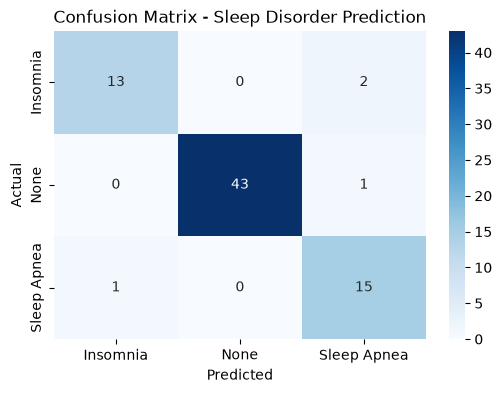

In [4]:
# Modeling
model = DecisionTreeClassifier(random_state=42, max_depth=5)
model.fit(X_train, y_train)

# Prediksi & Evaluasi
y_pred = model.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=label_encoders['Sleep Disorder'].classes_))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoders['Sleep Disorder'].classes_,
            yticklabels=label_encoders['Sleep Disorder'].classes_)
plt.title('Confusion Matrix - Sleep Disorder Prediction')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()